# Lab Problem Statement 6: Statistical Analysis of Physical Characteristics of Palmer Penguins

## R Programming Lab

**Topics:** Descriptive Statistics, Hypothesis Testing, ANOVA & Non-Parametric Tests

This is a **native R notebook**. It is intended to run with an **R runtime/kernel**, not Python or rpy2.

### Analysis covered
1. Descriptive statistics
2. Body-mass visualizations
3. Male vs female hypothesis testing
4. Shapiro-Wilk normality tests and QQ-plots
5. Independent two-sample t-test
6. 95% confidence interval
7. Cohen's d
8. One-way ANOVA
9. Levene's test
10. Tukey HSD
11. Kruskal-Wallis test
12. Two-way ANOVA
13. Interaction analysis
14. Flipper-length analysis
15. Final statistical summary

The assignment specifies the Palmer Penguins dataset and variables including species, island, flipper length, body mass and sex.

## 1. Install and Load Required R Packages

Run this cell once. If a package is already installed, R will simply load it.

In [1]:
required_packages <- c(
  "palmerpenguins",
  "ggplot2",
  "dplyr",
  "moments",
  "car",
  "effectsize"
)

installed <- rownames(installed.packages())

for (pkg in required_packages) {
  if (!(pkg %in% installed)) {
    install.packages(pkg, repos = "https://cloud.r-project.org")
  }
}

library(palmerpenguins)
library(ggplot2)
library(dplyr)
library(moments)
library(car)
library(effectsize)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘bayestestR’, ‘insight’, ‘parameters’, ‘performance’, ‘datawizard’



Attaching package: ‘palmerpenguins’


The following objects are masked from ‘package:datasets’:

    penguins, penguins_raw



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The follow

# 2. Load the Palmer Penguins Dataset

In [2]:
data("penguins")

cat("Number of observations:", nrow(penguins), "\n")
cat("Number of variables:", ncol(penguins), "\n\n")

head(penguins)

Number of observations: 344 
Number of variables: 8 



species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>,<int>
Adelie,Torgersen,39.1,18.7,181,3750,male,2007
Adelie,Torgersen,39.5,17.4,186,3800,female,2007
Adelie,Torgersen,40.3,18.0,195,3250,female,2007
Adelie,Torgersen,NA,NA,NA,NA,NA,2007
Adelie,Torgersen,36.7,19.3,193,3450,female,2007
Adelie,Torgersen,39.3,20.6,190,3650,male,2007


In [3]:
str(penguins)

cat("\nSummary:\n")
summary(penguins)

cat("\nMissing values:\n")
colSums(is.na(penguins))

tibble [344 × 8] (S3: tbl_df/tbl/data.frame)
 $ species          : Factor w/ 3 levels "Adelie","Chinstrap",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ island           : Factor w/ 3 levels "Biscoe","Dream",..: 3 3 3 3 3 3 3 3 3 3 ...
 $ bill_length_mm   : num [1:344] 39.1 39.5 40.3 NA 36.7 39.3 38.9 39.2 34.1 42 ...
 $ bill_depth_mm    : num [1:344] 18.7 17.4 18 NA 19.3 20.6 17.8 19.6 18.1 20.2 ...
 $ flipper_length_mm: int [1:344] 181 186 195 NA 193 190 181 195 193 190 ...
 $ body_mass_g      : int [1:344] 3750 3800 3250 NA 3450 3650 3625 4675 3475 4250 ...
 $ sex              : Factor w/ 2 levels "female","male": 2 1 1 NA 1 2 1 2 NA NA ...
 $ year             : int [1:344] 2007 2007 2007 2007 2007 2007 2007 2007 2007 2007 ...

Summary:


      species          island    bill_length_mm  bill_depth_mm  
 Adelie   :152   Biscoe   :168   Min.   :32.10   Min.   :13.10  
 Chinstrap: 68   Dream    :124   1st Qu.:39.23   1st Qu.:15.60  
 Gentoo   :124   Torgersen: 52   Median :44.45   Median :17.30  
                                 Mean   :43.92   Mean   :17.15  
                                 3rd Qu.:48.50   3rd Qu.:18.70  
                                 Max.   :59.60   Max.   :21.50  
                                 NAs    :2       NAs    :2      
 flipper_length_mm  body_mass_g       sex           year     
 Min.   :172.0     Min.   :2700   female:165   Min.   :2007  
 1st Qu.:190.0     1st Qu.:3550   male  :168   1st Qu.:2007  
 Median :197.0     Median :4050   NAs   : 11   Median :2008  
 Mean   :200.9     Mean   :4202                Mean   :2008  
 3rd Qu.:213.0     3rd Qu.:4750                3rd Qu.:2009  
 Max.   :231.0     Max.   :6300                Max.   :2009  
 NAs    :2         NAs    :2                  


Missing values:


species            island    bill_length_mm     bill_depth_mm 
                0                 0                 2                 2 
flipper_length_mm       body_mass_g               sex              year 
                2                 2                11                 0

# 3. Data Cleaning

For body-mass analyses involving species and sex, remove observations with missing values in those variables.

In [4]:
penguins_clean <- penguins %>%
  filter(
    !is.na(body_mass_g),
    !is.na(species),
    !is.na(sex)
  )

cat("Original observations:", nrow(penguins), "\n")
cat("Observations after cleaning:", nrow(penguins_clean), "\n\n")

cat("Species counts:\n")
print(table(penguins_clean$species))

cat("\nSex counts:\n")
print(table(penguins_clean$sex))

Original observations: 344 
Observations after cleaning: 333 

Species counts:

   Adelie Chinstrap    Gentoo 
      146        68       119 

Sex counts:

female   male 
   165    168 


# 4. Descriptive Statistical Analysis of Body Mass

Calculate:
- Mean
- Median
- Minimum and maximum
- Variance
- Standard deviation
- First and third quartiles
- IQR
- Skewness
- Kurtosis

In [5]:
body_mass_stats <- data.frame(
  Mean = mean(penguins_clean$body_mass_g),
  Median = median(penguins_clean$body_mass_g),
  Minimum = min(penguins_clean$body_mass_g),
  Maximum = max(penguins_clean$body_mass_g),
  Variance = var(penguins_clean$body_mass_g),
  Standard_Deviation = sd(penguins_clean$body_mass_g),
  Q1 = as.numeric(quantile(penguins_clean$body_mass_g, 0.25)),
  Q3 = as.numeric(quantile(penguins_clean$body_mass_g, 0.75)),
  IQR = IQR(penguins_clean$body_mass_g),
  Skewness = skewness(penguins_clean$body_mass_g),
  Kurtosis = kurtosis(penguins_clean$body_mass_g)
)

round(body_mass_stats, 3)

Mean,Median,Minimum,Maximum,Variance,Standard_Deviation,Q1,Q3,IQR,Skewness,Kurtosis
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4207.057,4050,2700,6300,648372.5,805.216,3550,4775,1225,0.47,2.26


## 4.1 Species-Wise Descriptive Statistics

In [7]:
species_stats <- penguins_clean %>%
  group_by(species) %>%
  summarise(
    N = n(),
    Mean = mean(body_mass_g),
    Median = median(body_mass_g),
    Minimum = min(body_mass_g),
    Maximum = max(body_mass_g),
    Variance = var(body_mass_g),
    SD = sd(body_mass_g),
    Q1 = as.numeric(quantile(body_mass_g, 0.25)),
    Q3 = as.numeric(quantile(body_mass_g, 0.75)),
    IQR = IQR(body_mass_g),
    Skewness = skewness(body_mass_g),
    Kurtosis = kurtosis(body_mass_g)
  )

species_stats %>%
  mutate(across(where(is.numeric), ~ round(.x, 3)))

species,N,Mean,Median,Minimum,Maximum,Variance,SD,Q1,Q3,IQR,Skewness,Kurtosis
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Adelie,146,3706.164,3700,2850,4775,210332.4,458.620,3362.5,4000,637.5,0.277,2.411
Chinstrap,68,3733.088,3700,2700,4800,147713.5,384.335,3487.5,3950,462.5,0.242,3.464
Gentoo,119,5092.437,5050,3950,6300,251478.3,501.476,4700.0,5500,800.0,0.045,2.243


# 5. Visualization of Body Mass

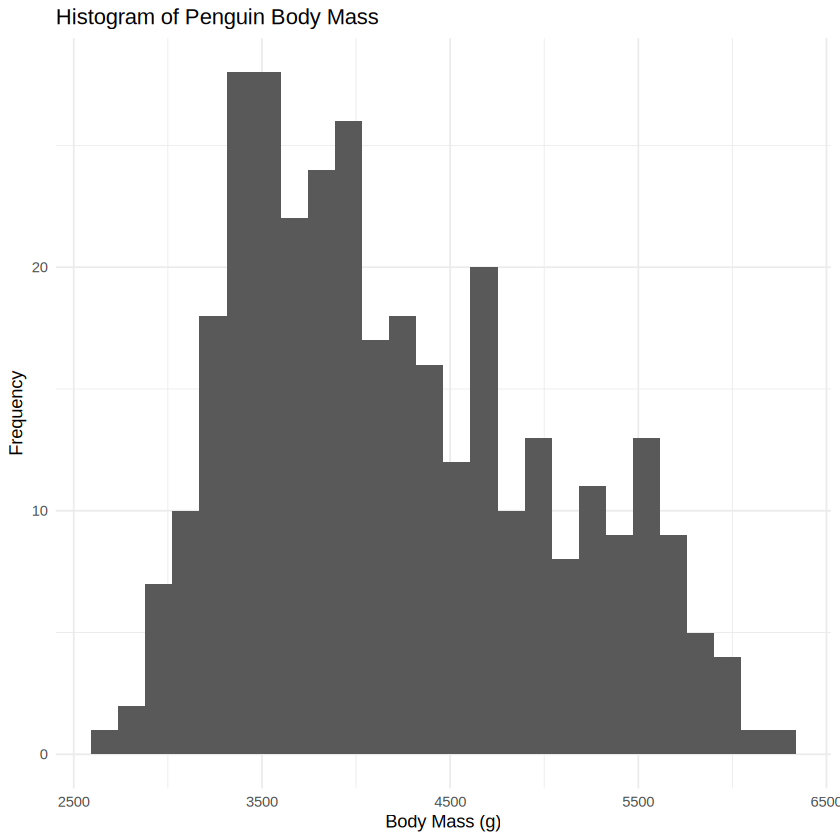

In [8]:
ggplot(penguins_clean, aes(x = body_mass_g)) +
  geom_histogram(bins = 25, boundary = 0) +
  labs(
    title = "Histogram of Penguin Body Mass",
    x = "Body Mass (g)",
    y = "Frequency"
  ) +
  theme_minimal()

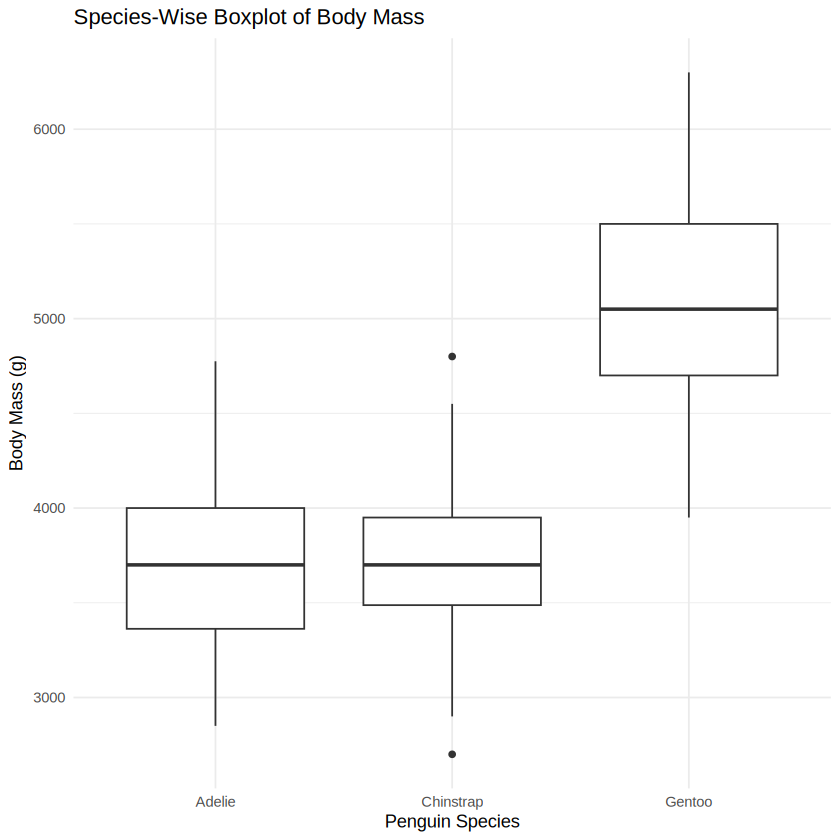

In [9]:
ggplot(penguins_clean, aes(x = species, y = body_mass_g)) +
  geom_boxplot() +
  labs(
    title = "Species-Wise Boxplot of Body Mass",
    x = "Penguin Species",
    y = "Body Mass (g)"
  ) +
  theme_minimal()

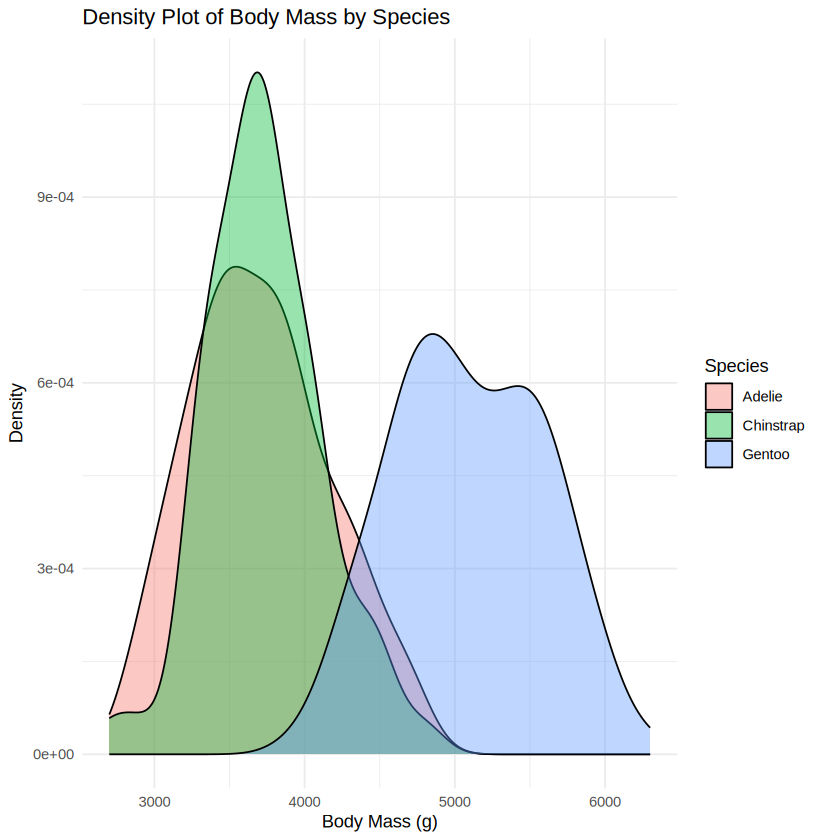

In [10]:
ggplot(penguins_clean, aes(x = body_mass_g, fill = species)) +
  geom_density(alpha = 0.4) +
  labs(
    title = "Density Plot of Body Mass by Species",
    x = "Body Mass (g)",
    y = "Density",
    fill = "Species"
  ) +
  theme_minimal()

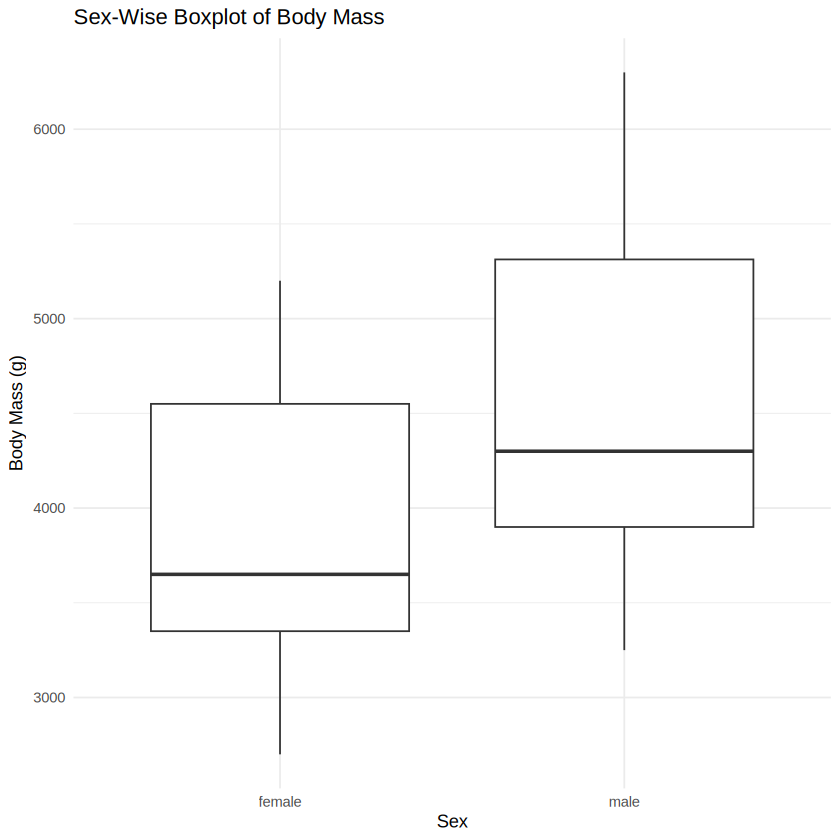

In [11]:
ggplot(penguins_clean, aes(x = sex, y = body_mass_g)) +
  geom_boxplot() +
  labs(
    title = "Sex-Wise Boxplot of Body Mass",
    x = "Sex",
    y = "Body Mass (g)"
  ) +
  theme_minimal()

# 6. Hypothesis Testing: Male vs Female Body Mass

### Null hypothesis (H₀)
Male and female penguins have the same mean body mass.

### Alternative hypothesis (H₁)
Male and female penguins have different mean body masses.

A two-sided independent two-sample t-test will be performed.

In [12]:
male_mass <- penguins_clean %>%
  filter(sex == "male") %>%
  pull(body_mass_g)

female_mass <- penguins_clean %>%
  filter(sex == "female") %>%
  pull(body_mass_g)

cat("Male mean:", mean(male_mass), "g\n")
cat("Female mean:", mean(female_mass), "g\n")

Male mean: 4545.685 g
Female mean: 3862.273 g


## 6.1 Shapiro-Wilk Normality Tests

In [13]:
cat("Male body mass:\n")
print(shapiro.test(male_mass))

cat("\nFemale body mass:\n")
print(shapiro.test(female_mass))

Male body mass:

	Shapiro-Wilk normality test

data:  male_mass
W = 0.92504, p-value = 1.227e-07


Female body mass:

	Shapiro-Wilk normality test

data:  female_mass
W = 0.91931, p-value = 6.155e-08



## 6.2 QQ-Plots

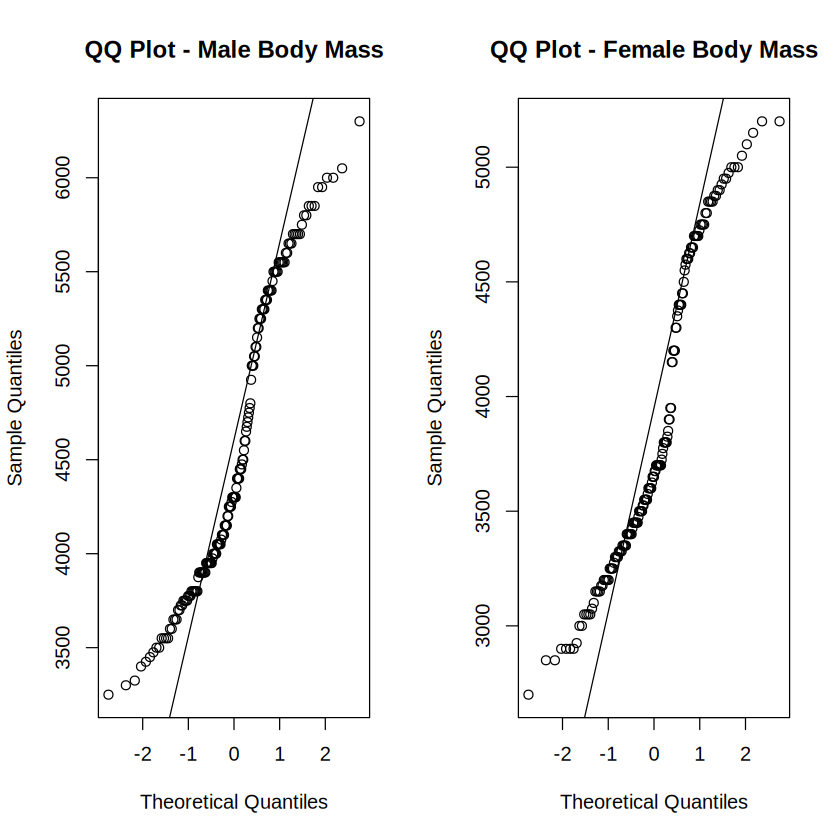

In [14]:
par(mfrow = c(1, 2))

qqnorm(male_mass, main = "QQ Plot - Male Body Mass")
qqline(male_mass)

qqnorm(female_mass, main = "QQ Plot - Female Body Mass")
qqline(female_mass)

par(mfrow = c(1, 1))

## 6.3 Independent Two-Sample t-Test

Welch's t-test is used because it does not assume equal population variances.

In [15]:
ttest_result <- t.test(
  male_mass,
  female_mass,
  alternative = "two.sided",
  conf.level = 0.95
)

print(ttest_result)


	Welch Two Sample t-test

data:  male_mass and female_mass
t = 8.5545, df = 323.9, p-value = 4.794e-16
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 526.2453 840.5783
sample estimates:
mean of x mean of y 
 4545.685  3862.273 



## 6.4 Cohen's d Effect Size

In [16]:
cohen_result <- cohens_d(
  body_mass_g ~ sex,
  data = penguins_clean,
  pooled_sd = TRUE
)

print(cohen_result)

Cohen's d |         95% CI
--------------------------
-0.94     | [-1.16, -0.71]

- Estimated using pooled SD.

### Interpretation

Use the p-value to determine statistical significance at α = 0.05.

- p < 0.05 → reject H₀.
- p ≥ 0.05 → fail to reject H₀.

The confidence interval gives a plausible range for the difference between the two population means.

Cohen's d describes practical effect size. Rough guidelines are approximately:
- 0.2 = small
- 0.5 = medium
- 0.8 = large

# 7. One-Way ANOVA: Body Mass by Species

Model:

`body_mass_g ~ species`

### H₀
The mean body mass is equal for all three species.

### H₁
At least one species has a different mean body mass.

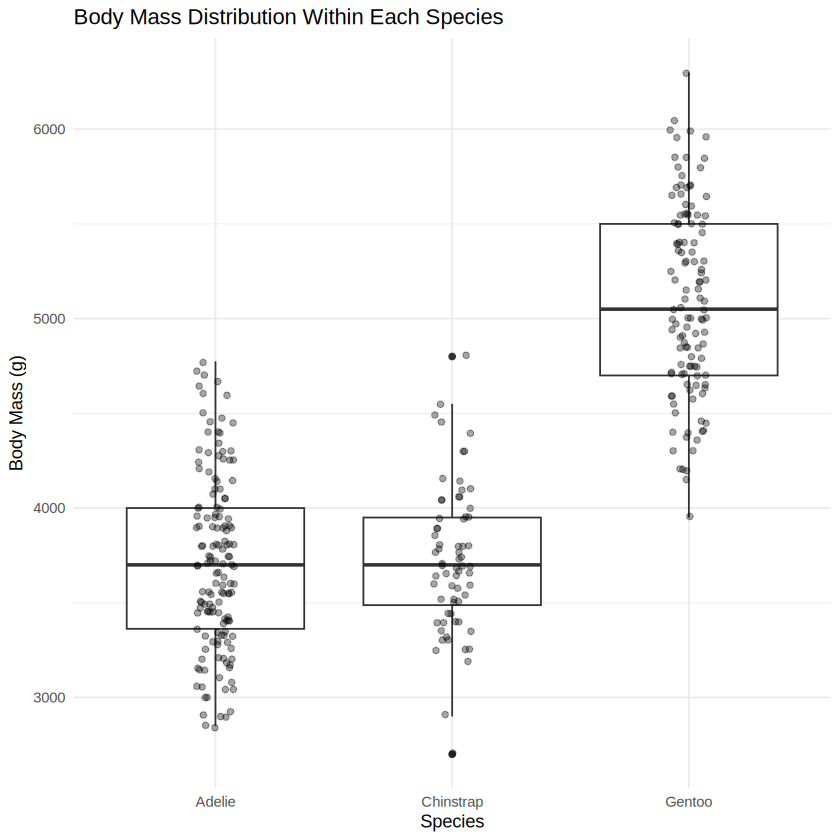

In [17]:
ggplot(penguins_clean, aes(x = species, y = body_mass_g)) +
  geom_boxplot() +
  geom_jitter(width = 0.08, alpha = 0.35) +
  labs(
    title = "Body Mass Distribution Within Each Species",
    x = "Species",
    y = "Body Mass (g)"
  ) +
  theme_minimal()

## 7.1 Normality Tests by Species

In [18]:
for (sp in levels(factor(penguins_clean$species))) {
  x <- penguins_clean %>%
    filter(species == sp) %>%
    pull(body_mass_g)

  cat("\n---", sp, "---\n")
  print(shapiro.test(x))
}


--- Adelie ---

	Shapiro-Wilk normality test

data:  x
W = 0.98116, p-value = 0.04232


--- Chinstrap ---

	Shapiro-Wilk normality test

data:  x
W = 0.98449, p-value = 0.5605


--- Gentoo ---

	Shapiro-Wilk normality test

data:  x
W = 0.98606, p-value = 0.2605



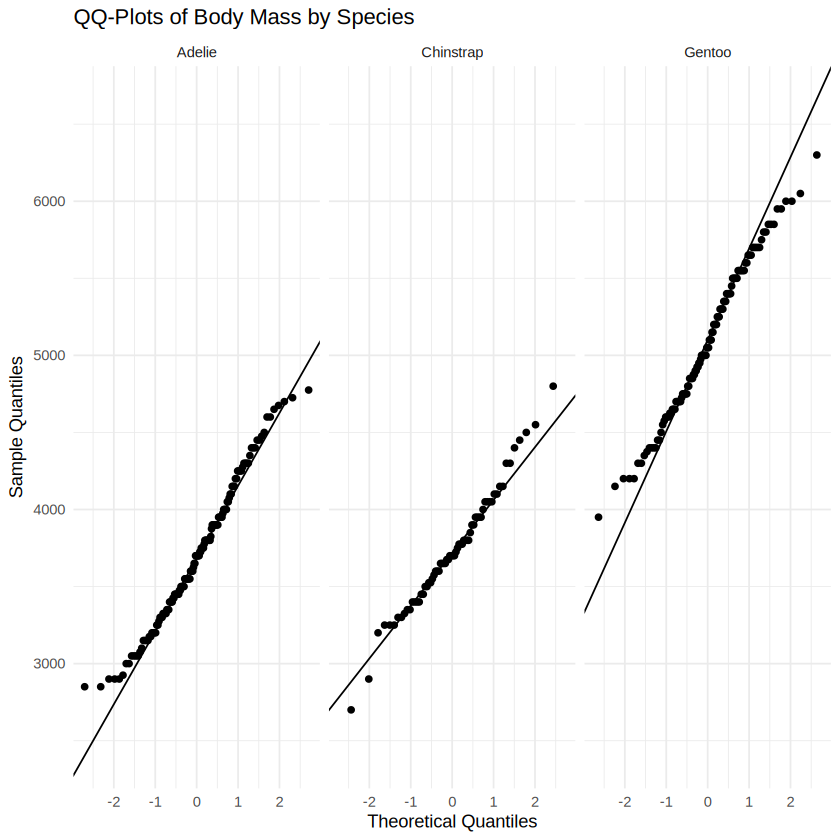

In [19]:
ggplot(penguins_clean, aes(sample = body_mass_g)) +
  stat_qq() +
  stat_qq_line() +
  facet_wrap(~ species) +
  labs(
    title = "QQ-Plots of Body Mass by Species",
    x = "Theoretical Quantiles",
    y = "Sample Quantiles"
  ) +
  theme_minimal()

## 7.2 Homogeneity of Variance — Levene's Test

In [20]:
levene_result <- leveneTest(
  body_mass_g ~ species,
  data = penguins_clean
)

print(levene_result)

Levene's Test for Homogeneity of Variance (center = median)
       Df F value   Pr(>F)   
group   2  5.1349 0.006367 **
      330                    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


## 7.3 One-Way ANOVA

In [21]:
anova_model <- aov(
  body_mass_g ~ species,
  data = penguins_clean
)

print(summary(anova_model))

             Df    Sum Sq  Mean Sq F value Pr(>F)    
species       2 145190219 72595110   341.9 <2e-16 ***
Residuals   330  70069447   212332                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


In [22]:
anova_table <- summary(anova_model)[[1]]

F_value <- anova_table[["F value"]][1]
df_between <- anova_table[["Df"]][1]
df_within <- anova_table[["Df"]][2]
anova_p <- anova_table[["Pr(>F)"]][1]

cat("F-statistic:", F_value, "\n")
cat("Degrees of freedom:", df_between, "and", df_within, "\n")
cat("p-value:", anova_p, "\n")

F-statistic: 341.8949 
Degrees of freedom: 2 and 330 
p-value: 3.744505e-81 


## 7.4 Tukey HSD Post-Hoc Test

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = body_mass_g ~ species, data = penguins_clean)

$species
                       diff       lwr       upr    p adj
Chinstrap-Adelie   26.92385 -132.3528  186.2005 0.916431
Gentoo-Adelie    1386.27259 1252.2897 1520.2554 0.000000
Gentoo-Chinstrap 1359.34874 1194.4304 1524.2671 0.000000



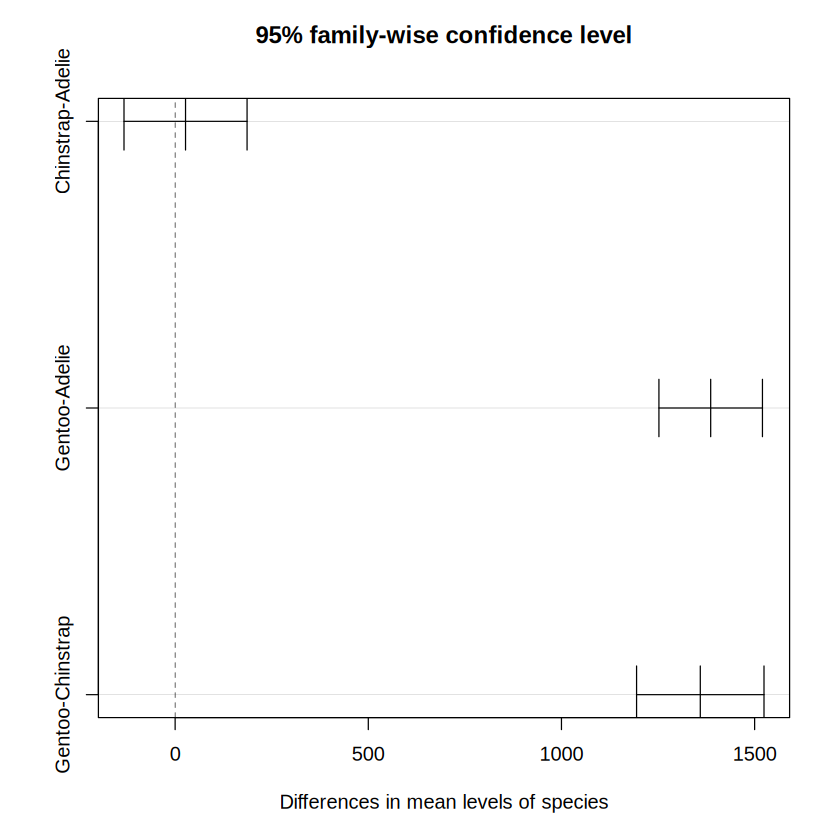

In [23]:
tukey_result <- TukeyHSD(anova_model)

print(tukey_result)

plot(tukey_result)

# 8. Non-Parametric Analysis — Kruskal-Wallis Test

In [24]:
kruskal_result <- kruskal.test(
  body_mass_g ~ species,
  data = penguins_clean
)

print(kruskal_result)


	Kruskal-Wallis rank sum test

data:  body_mass_g by species
Kruskal-Wallis chi-squared = 212.09, df = 2, p-value < 2.2e-16



In [25]:
cat("One-way ANOVA p-value:", anova_p, "\n")
cat("Kruskal-Wallis p-value:", kruskal_result$p.value, "\n")

One-way ANOVA p-value: 3.744505e-81 
Kruskal-Wallis p-value: 8.836877e-47 


### Comparison

Compare the ANOVA and Kruskal-Wallis p-values.

If both tests are statistically significant, they provide consistent evidence that body mass differs across species. If the conclusions differ, discuss the role of assumptions and the robustness of the non-parametric method.

# 9. Two-Way ANOVA: Species and Sex

Model:

`body_mass_g ~ species * sex`

This tests:
1. Main effect of species
2. Main effect of sex
3. Species × sex interaction

In [26]:
two_way_model <- aov(
  body_mass_g ~ species * sex,
  data = penguins_clean
)

summary(two_way_model)

             Df    Sum Sq  Mean Sq F value   Pr(>F)    
species       2 145190219 72595110 758.358  < 2e-16 ***
sex           1  37090262 37090262 387.460  < 2e-16 ***
species:sex   2   1676557   838278   8.757 0.000197 ***
Residuals   327  31302628    95727                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

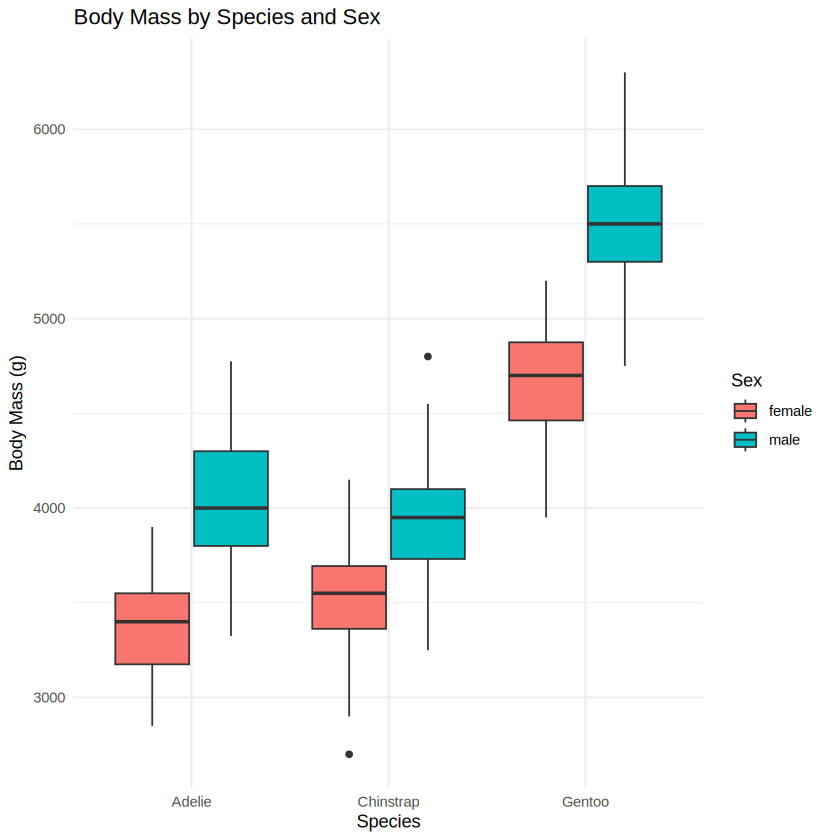

In [27]:
ggplot(penguins_clean, aes(x = species, y = body_mass_g, fill = sex)) +
  geom_boxplot(position = position_dodge(width = 0.8)) +
  labs(
    title = "Body Mass by Species and Sex",
    x = "Species",
    y = "Body Mass (g)",
    fill = "Sex"
  ) +
  theme_minimal()

## 9.1 Species × Sex Interaction Plot

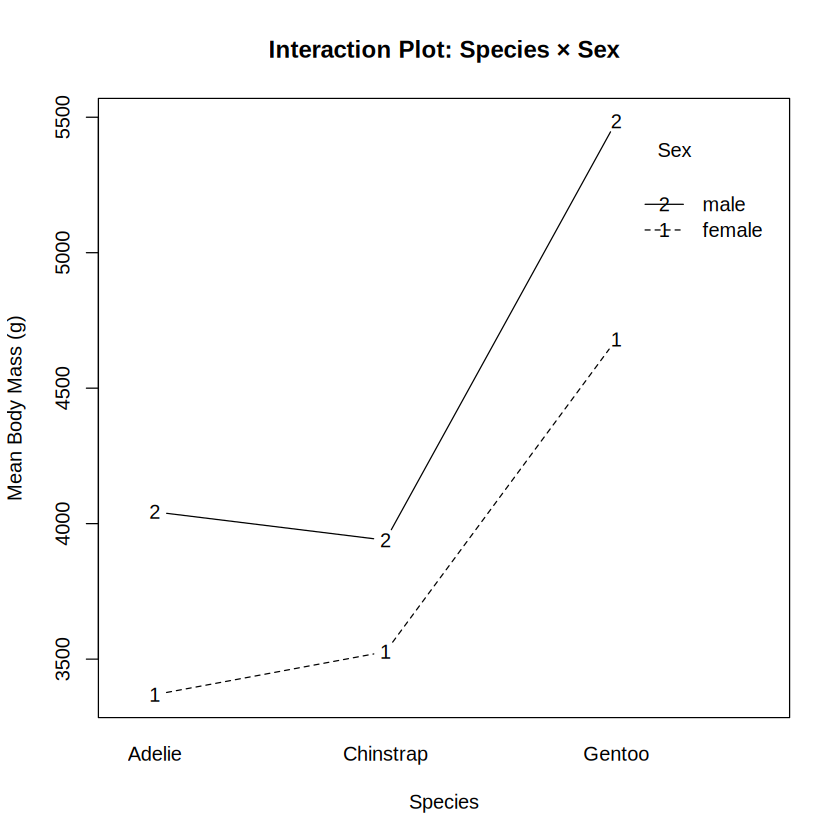

In [28]:
interaction.plot(
  x.factor = penguins_clean$species,
  trace.factor = penguins_clean$sex,
  response = penguins_clean$body_mass_g,
  fun = mean,
  type = "b",
  xlab = "Species",
  ylab = "Mean Body Mass (g)",
  trace.label = "Sex",
  main = "Interaction Plot: Species × Sex"
)

### Interpretation

- Significant species effect → species is associated with body-mass differences.
- Significant sex effect → sex is associated with body-mass differences.
- Significant interaction → the effect of sex differs depending on species.

# 10. Additional Analysis — Flipper Length

The assignment asks for an appropriate part of the analysis to be repeated using `flipper_length_mm`.

In [29]:
flipper_clean <- penguins %>%
  filter(
    !is.na(flipper_length_mm),
    !is.na(species)
  )

flipper_stats <- flipper_clean %>%
  group_by(species) %>%
  summarise(
    N = n(),
    Mean = mean(flipper_length_mm),
    Median = median(flipper_length_mm),
    SD = sd(flipper_length_mm),
    Minimum = min(flipper_length_mm),
    Maximum = max(flipper_length_mm)
  )

round(flipper_stats, 3)

ERROR: Error in Math.data.frame(structure(list(species = structure(1:3, levels = c("Adelie", : non-numeric-alike variable(s) in data frame: species


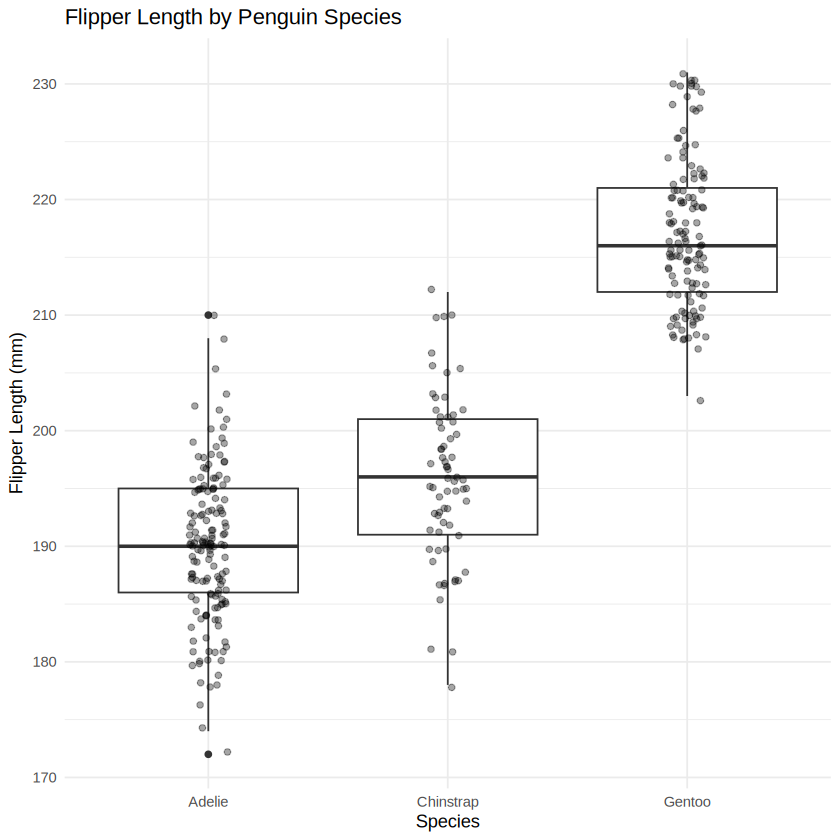

In [30]:
ggplot(flipper_clean, aes(x = species, y = flipper_length_mm)) +
  geom_boxplot() +
  geom_jitter(width = 0.08, alpha = 0.35) +
  labs(
    title = "Flipper Length by Penguin Species",
    x = "Species",
    y = "Flipper Length (mm)"
  ) +
  theme_minimal()

## 10.1 Flipper Length — One-Way ANOVA

In [31]:
flipper_anova <- aov(
  flipper_length_mm ~ species,
  data = flipper_clean
)

print(summary(flipper_anova))

             Df Sum Sq Mean Sq F value Pr(>F)    
species       2  52473   26237   594.8 <2e-16 ***
Residuals   339  14953      44                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


## 10.2 Flipper Length — Tukey HSD

In [32]:
print(TukeyHSD(flipper_anova))

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = flipper_length_mm ~ species, data = flipper_clean)

$species
                      diff       lwr       upr p adj
Chinstrap-Adelie  5.869887  3.586583  8.153191     0
Gentoo-Adelie    27.233349 25.334376 29.132323     0
Gentoo-Chinstrap 21.363462 19.000841 23.726084     0



## 10.3 Flipper Length — Kruskal-Wallis

In [33]:
flipper_kruskal <- kruskal.test(
  flipper_length_mm ~ species,
  data = flipper_clean
)

print(flipper_kruskal)


	Kruskal-Wallis rank sum test

data:  flipper_length_mm by species
Kruskal-Wallis chi-squared = 244.89, df = 2, p-value < 2.2e-16



# 11. Group Comparison Plot with 95% Confidence Intervals

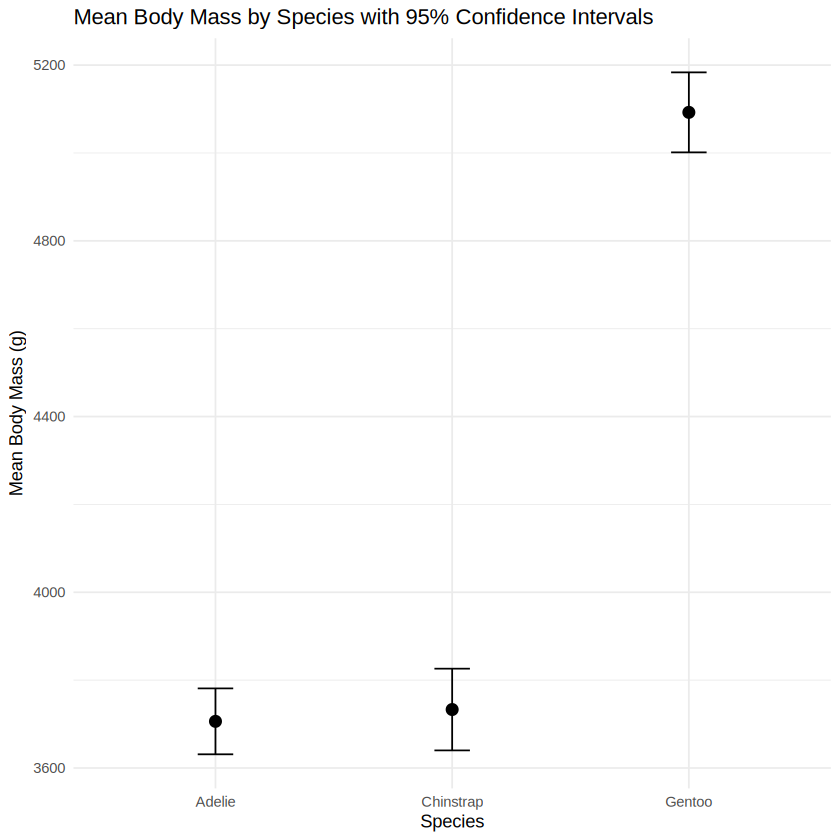

In [34]:
species_summary <- penguins_clean %>%
  group_by(species) %>%
  summarise(
    mean_mass = mean(body_mass_g),
    sd_mass = sd(body_mass_g),
    n = n(),
    se = sd_mass / sqrt(n),
    lower = mean_mass - qt(0.975, df = n - 1) * se,
    upper = mean_mass + qt(0.975, df = n - 1) * se
  )

ggplot(species_summary, aes(x = species, y = mean_mass)) +
  geom_point(size = 3) +
  geom_errorbar(
    aes(ymin = lower, ymax = upper),
    width = 0.15
  ) +
  labs(
    title = "Mean Body Mass by Species with 95% Confidence Intervals",
    x = "Species",
    y = "Mean Body Mass (g)"
  ) +
  theme_minimal()

# 12. Final Statistical Summary

In [35]:
cat("============================================\n")
cat("FINAL STATISTICAL SUMMARY\n")
cat("============================================\n\n")

cat("A. Male vs Female t-test\n")
cat("p-value:", format.pval(ttest_result$p.value), "\n")
cat(
  "95% CI:",
  paste(round(ttest_result$conf.int, 2), collapse = " to "),
  "\n\n"
)

cat("B. One-way ANOVA: Body Mass ~ Species\n")
cat("F-statistic:", round(F_value, 4), "\n")
cat("df:", df_between, "and", df_within, "\n")
cat("p-value:", format.pval(anova_p), "\n\n")

cat("C. Kruskal-Wallis: Body Mass ~ Species\n")
cat("p-value:", format.pval(kruskal_result$p.value), "\n\n")

cat("D. Two-way ANOVA: Body Mass ~ Species * Sex\n")
print(summary(two_way_model))

cat("\nE. Flipper Length ANOVA\n")
print(summary(flipper_anova))

cat("\nF. Flipper Length Kruskal-Wallis\n")
print(flipper_kruskal)

FINAL STATISTICAL SUMMARY

A. Male vs Female t-test
p-value: 4.7939e-16 
95% CI: 526.25 to 840.58 

B. One-way ANOVA: Body Mass ~ Species
F-statistic: 341.8949 
df: 2 and 330 
p-value: < 2.22e-16 

C. Kruskal-Wallis: Body Mass ~ Species
p-value: < 2.22e-16 

D. Two-way ANOVA: Body Mass ~ Species * Sex
             Df    Sum Sq  Mean Sq F value   Pr(>F)    
species       2 145190219 72595110 758.358  < 2e-16 ***
sex           1  37090262 37090262 387.460  < 2e-16 ***
species:sex   2   1676557   838278   8.757 0.000197 ***
Residuals   327  31302628    95727                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

E. Flipper Length ANOVA
             Df Sum Sq Mean Sq F value Pr(>F)    
species       2  52473   26237   594.8 <2e-16 ***
Residuals   339  14953      44                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

F. Flipper Length Kruskal-Wallis

	Kruskal-Wallis rank sum test

data:  flipper_length_mm by species
Kruska

# 13. Final Conclusion

### Write your conclusion from the actual results above.

**Descriptive statistics:**  
Describe the overall body-mass distribution and compare the three species.

**Male vs female test:**  
Report the two-sample t-test p-value, 95% confidence interval and Cohen's d. State whether the difference is statistically significant.

**One-way ANOVA:**  
Report the F-statistic, degrees of freedom and p-value. If significant, use Tukey HSD to identify the species pairs that differ.

**Kruskal-Wallis:**  
Compare its conclusion with the ANOVA result.

**Two-way ANOVA:**  
Discuss the effects of species, sex and their interaction.

**Flipper length:**  
Report whether flipper length varies significantly among species and compare the conclusion with the body-mass analysis.

> Important: Do not invent numerical values in the written conclusion. Use the values generated by the cells above.

# 14. Submission Checklist

- [x] Complete R analysis
- [x] Descriptive statistics
- [x] Species-wise statistics
- [x] Histogram
- [x] Body-mass boxplot
- [x] Density plot
- [x] Sex-wise boxplot
- [x] Shapiro-Wilk tests
- [x] QQ-plots
- [x] Independent two-sample t-test
- [x] 95% confidence interval
- [x] Cohen's d
- [x] One-way ANOVA
- [x] Levene's test
- [x] Tukey HSD
- [x] Kruskal-Wallis
- [x] Two-way ANOVA
- [x] Interaction plot
- [x] Flipper-length analysis
- [x] Group comparison plot
- [x] Final statistical summary
- [x] Conclusion template

The assignment requires submission of the **Colab notebook PDF** and a Git upload/link. Run every cell first so the PDF contains the numerical results and graphs.